# CardioIA, Fase 3, Ir Além 2: IA em séries temporais de saúde

**Regressão logística versus rede neuromórfica simples (neurônio LIF) na classificação de episódios de risco em séries de frequência cardíaca**

Projeto CardioIA (FIAP, curso de Inteligência Artificial, Ano 2), Fase 3, Grupo 55. Aluno: Silvio Prestes Guerreiro Junior, RM 567958, turma 2TIAOR. Tutor: Leonardo Ruiz Orabona. Coordenador: André Godoi Chiovato. Data: 31/10/2026.

## 1. Objetivo

O wearable simulado das Partes 1 e 2 desta fase produz uma série temporal de frequência cardíaca (uma amostra a cada 5 s, com indicador de movimento) e avalia alertas por limiares fixos (acima de 120 bpm, abaixo de 50 bpm). Este notebook pergunta o que um classificador aprendido acrescenta a esses limiares e compara duas abordagens sobre janelas de 2 minutos da série:

1. um classificador tradicional, a **regressão logística** sobre características estatísticas da janela (scikit-learn);
2. uma **rede neuromórfica simples**: codificação das mesmas características em trens de disparos (codificação por taxa com campos receptivos gaussianos) e dois neurônios **LIF** (leaky integrate-and-fire) de saída, treinados por uma regra supervisionada de taxa de disparo, implementados em NumPy.

As duas abordagens são avaliadas com as mesmas janelas e métricas (acurácia, precisão, sensibilidade, F1 e matriz de confusão), comparadas em custo computacional, latência de decisão e interpretabilidade, e aplicadas à série real registrada pelo protótipo no Wokwi. A discussão retoma o capítulo 3 do curso (Cérebros de Silício na Era dos Chips Neuromórficos), que descreve o modelo de integração e disparo dos chips TrueNorth e Loihi e mostra que redes impulsionais executadas em arquitetura Von Neumann não entregam, por si só, ganho energético.

Os dados de treino são **sintéticos e documentados** (seção 3), porque não há base pública de frequência cardíaca amostrada a 5 s com rótulos de episódio compatíveis com o protótipo e porque o uso de dados reais de pacientes exigiria base legal e anonimização (LGPD). A série real do protótipo (seção 8) é pequena e serve apenas para demonstrar a inferência de ponta a ponta.

## 2. Configuração e reprodutibilidade

Todas as operações aleatórias usam sementes fixas. As figuras são gravadas em `assets/figuras/ir_alem2/` e os dados do protótipo são lidos de `src/ir_alem2_ia_series/dados/`. O notebook localiza a raiz do repositório procurando o `README.md` principal, para funcionar no VS Code, no JupyterLab e no Google Colab (após o clone).

In [1]:
import os, sys, time, json, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
SEMENTE = 55
rng = np.random.default_rng(SEMENTE)

# raiz do repositorio: sobe ate encontrar o README.md principal
RAIZ = Path.cwd()
for _ in range(5):
    if (RAIZ / "README.md").exists() and (RAIZ / "src").exists():
        break
    RAIZ = RAIZ.parent
PASTA_DADOS = RAIZ / "src" / "ir_alem2_ia_series" / "dados"
PASTA_FIG = RAIZ / "assets" / "figuras" / "ir_alem2"
PASTA_FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("raiz:", RAIZ.name, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

raiz: 03_entrega | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 3. Dados

### 3.1 Série real do protótipo

Os arquivos `prototipo_parte1_2026-10-30.csv` e `prototipo_parte2_2026-10-30.csv` foram extraídos dos logs do monitor serial do Wokwi (`scripts/extrair_series_prototipo.py`). O valor `bpm = 0` significa ausência de leitura (nenhuma pressão no botão que simula os batimentos nos últimos 5 s), não parada cardíaca; na análise ele é tratado como dado ausente e preenchido com a última leitura válida.

In [2]:
proto1 = pd.read_csv(PASTA_DADOS / "prototipo_parte1_2026-10-30.csv")
proto2 = pd.read_csv(PASTA_DADOS / "prototipo_parte2_2026-10-30.csv")
print("Parte 1:", len(proto1), "amostras | bpm > 0 em", int((proto1.bpm > 0).sum()), "| alertas distintos:", sorted(proto1.alertas.unique()))
print("Parte 2:", len(proto2), "amostras | bpm > 0 em", int((proto2.bpm > 0).sum()))
proto1.head(8)

Parte 1: 53 amostras | bpm > 0 em 6 | alertas distintos: [np.int64(0), np.int64(1), np.int64(8), np.int64(16)]
Parte 2: 23 amostras | bpm > 0 em 4


,ts,temp_c,umid_pct,bpm,mov,alertas,origem
0,3,24.0,40.0,0,0,8,online
1,8,24.0,40.0,0,0,8,online
2,13,24.0,40.0,0,0,8,online
3,18,24.0,40.0,0,0,8,online
4,23,24.0,40.0,0,0,8,online
5,28,24.0,40.0,0,0,8,online
6,33,24.0,40.0,0,0,8,online
7,38,24.0,40.0,0,0,8,offline


### 3.2 Gerador de séries sintéticas (documentado)

Cada **episódio** tem 24 amostras com passo de 5 s (2 minutos), como as janelas que o dashboard e a API poderiam avaliar. Cinco subtipos são gerados, com parâmetros sorteados dentro de faixas fisiologicamente plausíveis:

| Subtipo | Rótulo | Descrição |
|---|---|---|
| `normal_repouso` | normal | linha de base entre 58 e 92 bpm, variabilidade batimento a batimento de 2 a 5 bpm, deriva lenta senoidal, movimento esporádico |
| `normal_atividade` | normal | trecho de atividade física com `mov = 1`: a frequência sobe até 100 a 135 bpm e volta; é fisiológico, mas um limiar fixo de 120 bpm dispararia alerta |
| `risco_taquicardia` | risco | em repouso (`mov = 0`), a frequência sobe em rampa para 125 a 170 bpm e permanece alta por pelo menos metade da janela |
| `risco_bradicardia` | risco | frequência cai para 32 a 48 bpm e permanece baixa |
| `risco_arritmia` | risco | média normal (65 a 110 bpm), mas ritmo irregular: diferenças sucessivas com desvio de 12 a 28 bpm e saltos abruptos, como em uma fibrilação atrial de resposta ventricular controlada; limiares fixos não detectam |

O rótulo vem do **subtipo gerado**, não dos limiares; assim o problema não se reduz a reaprender a regra do firmware, e os casos `normal_atividade` e `risco_arritmia` medem exatamente o que a regra fixa erra. O conjunto tem 1.200 episódios balanceados (600 normais: 420 repouso e 180 atividade; 600 de risco: 240 taquicardia, 120 bradicardia, 240 arritmia). A frequência é arredondada para inteiro e limitada a [30, 200] bpm, como a saída do firmware.

In [3]:
N_AMOSTRAS = 24          # 24 x 5 s = 2 minutos por episodio
PASSO_S = 5

def episodio(subtipo, rng):
    '''Gera um episodio sintetico (bpm e movimento) do subtipo pedido.'''
    t = np.arange(N_AMOSTRAS)
    mov = (rng.random(N_AMOSTRAS) < 0.08).astype(int)          # movimento esporadico de repouso
    if subtipo == "normal_repouso":
        base = rng.uniform(58, 92)
        deriva = rng.uniform(1, 4) * np.sin(2 * np.pi * t / rng.uniform(16, 40) + rng.uniform(0, 6.28))
        bpm = base + deriva + rng.normal(0, rng.uniform(2, 5), N_AMOSTRAS)
    elif subtipo == "normal_atividade":
        base = rng.uniform(62, 85)
        inicio, dur = rng.integers(2, 8), rng.integers(8, 14)
        pico = rng.uniform(100, 135)
        perfil = np.zeros(N_AMOSTRAS)
        for i in range(N_AMOSTRAS):
            if inicio <= i < inicio + dur:
                perfil[i] = (pico - base) * min(1.0, (i - inicio + 1) / 4)
            elif i >= inicio + dur:
                perfil[i] = (pico - base) * math.exp(-(i - inicio - dur + 1) / 3)
        bpm = base + perfil + rng.normal(0, 3, N_AMOSTRAS)
        mov = np.where((t >= inicio) & (t < inicio + dur), 1, mov)
    elif subtipo == "risco_taquicardia":
        base = rng.uniform(70, 95)
        inicio = rng.integers(0, N_AMOSTRAS // 2)
        pico = rng.uniform(125, 170)
        rampa = np.clip((t - inicio + 1) / rng.uniform(2, 5), 0, 1)
        bpm = base + (pico - base) * rampa + rng.normal(0, 4, N_AMOSTRAS)
        mov = np.zeros(N_AMOSTRAS, dtype=int)
    elif subtipo == "risco_bradicardia":
        base = rng.uniform(60, 75)
        inicio = rng.integers(0, N_AMOSTRAS // 2)
        piso = rng.uniform(32, 48)
        rampa = np.clip((t - inicio + 1) / rng.uniform(2, 5), 0, 1)
        bpm = base - (base - piso) * rampa + rng.normal(0, 2.5, N_AMOSTRAS)
    elif subtipo == "risco_arritmia":
        base = rng.uniform(65, 110)
        irregular = rng.normal(0, rng.uniform(12, 28), N_AMOSTRAS)
        saltos = rng.choice([0, 1], N_AMOSTRAS, p=[0.8, 0.2]) * rng.uniform(-35, 35, N_AMOSTRAS)
        bpm = base + irregular + saltos
    else:
        raise ValueError(subtipo)
    bpm = np.clip(np.round(bpm), 30, 200).astype(int)
    return bpm, mov

SUBTIPOS = {"normal_repouso": 420, "normal_atividade": 180, "risco_taquicardia": 240, "risco_bradicardia": 120, "risco_arritmia": 240}
registros = []
for subtipo, n in SUBTIPOS.items():
    for k in range(n):
        bpm, mov = episodio(subtipo, rng)
        registros.append({"subtipo": subtipo, "rotulo": 1 if subtipo.startswith("risco") else 0, "bpm": bpm, "mov": mov})
episodios = pd.DataFrame(registros)
print(episodios.subtipo.value_counts().to_string())
print("total:", len(episodios), "| risco:", int(episodios.rotulo.sum()), "| normal:", int((episodios.rotulo == 0).sum()))

subtipo
normal_repouso       420
risco_taquicardia    240
risco_arritmia       240
normal_atividade     180
risco_bradicardia    120
total: 1200 | risco: 600 | normal: 600


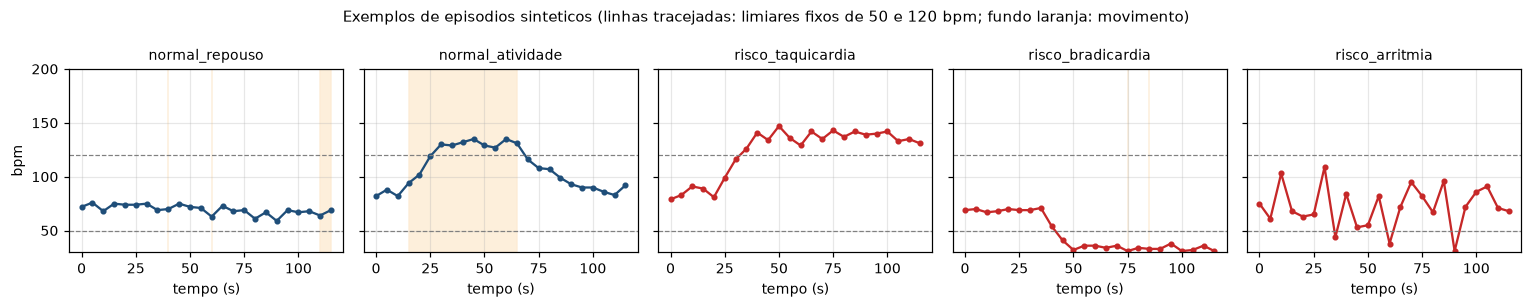

In [4]:
fig, eixos = plt.subplots(1, 5, figsize=(14, 2.8), sharey=True)
for eixo, subtipo in zip(eixos, SUBTIPOS):
    ex = episodios[episodios.subtipo == subtipo].iloc[0]
    tempo = np.arange(N_AMOSTRAS) * PASSO_S
    eixo.plot(tempo, ex.bpm, marker="o", ms=3, color="#c62828" if ex.rotulo else "#1f4e79")
    eixo.fill_between(tempo, 30, 200, where=ex.mov == 1, color="#fdebd3", alpha=0.8, label="movimento")
    eixo.axhline(120, color="gray", ls="--", lw=0.8); eixo.axhline(50, color="gray", ls="--", lw=0.8)
    eixo.set_title(subtipo, fontsize=9); eixo.set_xlabel("tempo (s)")
eixos[0].set_ylabel("bpm"); eixos[0].set_ylim(30, 200)
fig.suptitle("Exemplos de episodios sinteticos (linhas tracejadas: limiares fixos de 50 e 120 bpm; fundo laranja: movimento)", fontsize=10)
fig.tight_layout(); fig.savefig(PASTA_FIG / "exemplos_episodios.png", bbox_inches="tight"); plt.show()

### 3.3 Características por janela e divisão treino/teste

As duas abordagens recebem as mesmas doze características calculadas sobre cada janela: média, desvio padrão, mínimo, máximo, percentis 10 e 90, inclinação (ajuste linear), RMSSD (raiz da média dos quadrados das diferenças sucessivas, medida clássica de variabilidade), fração de amostras acima de 120 bpm, fração abaixo de 50 bpm, fração de amostras com movimento e média da frequência nas amostras sem movimento (frequência de repouso). A divisão é estratificada por subtipo, 70% para treino e 30% para teste, com semente fixa; nenhuma janela de teste participa do ajuste das escalas, dos campos receptivos ou dos pesos.

In [5]:
NOMES_CARACT = ["media", "desvio", "minimo", "maximo", "p10", "p90", "inclinacao", "rmssd", "frac_acima_120", "frac_abaixo_50", "frac_mov", "media_repouso"]

def caracteristicas(bpm, mov):
    bpm = np.asarray(bpm, dtype=float); mov = np.asarray(mov)
    dif = np.diff(bpm)
    t = np.arange(len(bpm))
    inclinacao = np.polyfit(t, bpm, 1)[0] if len(bpm) > 1 else 0.0
    repouso = bpm[mov == 0]
    return np.array([bpm.mean(), bpm.std(), bpm.min(), bpm.max(), np.percentile(bpm, 10), np.percentile(bpm, 90), inclinacao,
                     np.sqrt(np.mean(dif ** 2)) if len(dif) else 0.0, np.mean(bpm > 120), np.mean(bpm < 50), mov.mean(),
                     repouso.mean() if len(repouso) else bpm.mean()])

X = np.vstack([caracteristicas(b, m) for b, m in zip(episodios.bpm, episodios.mov)])
y = episodios.rotulo.values
sub = episodios.subtipo.to_numpy()   # ndarray (com pyarrow, .values seria ArrowStringArray e o split falharia)
X_tr, X_te, y_tr, y_te, sub_tr, sub_te = train_test_split(X, y, sub, test_size=0.30, random_state=SEMENTE, stratify=sub)
print("treino:", X_tr.shape, "| teste:", X_te.shape)
pd.DataFrame(X, columns=NOMES_CARACT).describe().loc[["mean", "std", "min", "max"]].round(2)

treino: (840, 12) | teste: (360, 12)


,media,desvio,minimo,maximo,p10,p90,inclinacao,rmssd,frac_acima_120,frac_abaixo_50,frac_mov,media_repouso
mean,88.91,14.39,63.23,111.58,70.76,105.03,0.45,11.10,0.18,0.08,0.12,86.91
std,26.20,9.77,17.28,33.31,20.05,31.54,1.47,10.08,0.29,0.21,0.17,26.18
min,36.46,1.04,30.00,54.00,30.00,38.70,-2.48,1.29,0.00,0.00,0.00,36.62
max,166.79,46.36,116.00,183.00,162.60,174.70,5.86,52.37,0.96,0.96,0.62,166.79


## 4. Linha de base: a regra de limiares do firmware

Para contextualizar os classificadores, a mesma regra avaliada no ESP32 e no Node-RED é aplicada às janelas: há risco se alguma amostra tem frequência acima de 120 bpm ou abaixo de 50 bpm. Como esperado pelo desenho dos dados, a regra acerta taquicardia e bradicardia, dispara em falso na atividade física e não enxerga a arritmia com média normal.

In [6]:
def metricas(y_real, y_pred):
    return {"acuracia": accuracy_score(y_real, y_pred), "precisao": precision_score(y_real, y_pred, zero_division=0),
            "sensibilidade": recall_score(y_real, y_pred, zero_division=0), "f1": f1_score(y_real, y_pred, zero_division=0)}

def regra_limiares(X_):
    return ((X_[:, NOMES_CARACT.index("frac_acima_120")] > 0) | (X_[:, NOMES_CARACT.index("frac_abaixo_50")] > 0)).astype(int)

y_regra = regra_limiares(X_te)
res_regra = metricas(y_te, y_regra)
print({k: round(v, 3) for k, v in res_regra.items()})
print("acerto por subtipo (teste):")
print(pd.Series(y_regra == y_te).groupby(sub_te).mean().round(3).to_string())

{'acuracia': 0.897, 'precisao': 0.842, 'sensibilidade': 0.978, 'f1': 0.905}
acerto por subtipo (teste):
normal_atividade     0.426
normal_repouso       0.984
risco_arritmia       0.944
risco_bradicardia    1.000
risco_taquicardia    1.000


## 5. Classificador tradicional: regressão logística

Pipeline com padronização e regressão logística (`C = 1`, `class_weight = "balanced"`), validação cruzada estratificada com 5 partições no treino e avaliação única no teste. A regressão logística é o padrão de referência para este tipo de problema por ser rápida, estável em bases pequenas e interpretável pelos coeficientes.

In [7]:
modelo_rl = Pipeline([("escala", StandardScaler()), ("rl", LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=SEMENTE))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
cv_acc = cross_val_score(modelo_rl, X_tr, y_tr, cv=cv, scoring="accuracy")
cv_f1 = cross_val_score(modelo_rl, X_tr, y_tr, cv=cv, scoring="f1")
t0 = time.perf_counter(); modelo_rl.fit(X_tr, y_tr); tempo_treino_rl = time.perf_counter() - t0
t0 = time.perf_counter(); y_rl = modelo_rl.predict(X_te); tempo_inf_rl = (time.perf_counter() - t0) / len(X_te)
res_rl = metricas(y_te, y_rl)
print(f"validacao cruzada (treino): acuracia {cv_acc.mean():.3f} +- {cv_acc.std():.3f} | F1 {cv_f1.mean():.3f} +- {cv_f1.std():.3f}")
print("teste:", {k: round(v, 3) for k, v in res_rl.items()})
print(f"treino {tempo_treino_rl*1000:.1f} ms | inferencia {tempo_inf_rl*1e6:.1f} us por janela")
print("acerto por subtipo (teste):")
print(pd.Series(y_rl == y_te).groupby(sub_te).mean().round(3).to_string())
coef = pd.Series(modelo_rl.named_steps["rl"].coef_[0], index=NOMES_CARACT).sort_values()
print("\ncoeficientes padronizados (positivo favorece risco):")
print(coef.round(2).to_string())

validacao cruzada (treino): acuracia 0.996 +- 0.003 | F1 0.996 +- 0.003
teste: {'acuracia': 1.0, 'precisao': 1.0, 'sensibilidade': 1.0, 'f1': 1.0}
treino 1.6 ms | inferencia 0.8 us por janela
acerto por subtipo (teste):
normal_atividade     1.0
normal_repouso       1.0
risco_arritmia       1.0
risco_bradicardia    1.0
risco_taquicardia    1.0

coeficientes padronizados (positivo favorece risco):
frac_mov         -2.23
minimo           -1.30
p10              -0.21
inclinacao       -0.10
media             0.44
p90               0.45
frac_acima_120    0.78
desvio            1.03
maximo            1.14
media_repouso     1.37
rmssd             2.33
frac_abaixo_50    3.19


## 6. Rede neuromórfica simples: codificação por taxa e neurônios LIF

### 6.1 Modelo

O neurônio **LIF** integra a corrente de entrada em um potencial de membrana com vazamento e dispara ao cruzar um limiar, exatamente a dinâmica que o capítulo 3 descreve nos núcleos neurossinápticos do TrueNorth (integração, vazamento, comparação com limiar e disparo). Em tempo discreto, com passo $\Delta t$:

$$V[t+1] = V[t] + \frac{\Delta t}{\tau_m}\bigl(-V[t] + R\,I[t]\bigr), \qquad I[t] = \sum_i W_{ik}\, s_i[t], \qquad \text{se } V \ge V_{th}: \text{disparo}, V \leftarrow V_{reset}$$

A rede tem uma camada: as doze características são **codificadas por taxa** com campos receptivos gaussianos (6 neurônios de entrada por característica, centros igualmente espaçados em [0, 1] após normalização mínimo-máximo ajustada no treino), gerando 72 trens de disparos de Poisson com taxa máxima de 200 Hz durante 100 ms; dois neurônios LIF de saída representam as classes normal e risco. A decisão é da saída que mais disparou (desempate pelo potencial final). Os pesos sinápticos são aprendidos por uma **regra supervisionada de taxa**: para cada janela de treino, a contagem de disparos de cada saída é comparada a uma contagem-alvo (alta para a classe correta, baixa para a outra) e os pesos são ajustados proporcionalmente ao erro e à taxa média de cada entrada, uma regra delta aplicada a contagens de disparos. É deliberadamente simples (sem gradiente substituto nem STDP) para que cada passo seja legível e implementável em um microcontrolador.

In [8]:
class RedeLIF:
    '''Codificacao por taxa (campos receptivos gaussianos) + 2 neuronios LIF de saida treinados por regra delta de taxa.'''
    def __init__(self, n_caract, n_rf=6, sigma=0.15, taxa_max_hz=200.0, T_ms=100, dt_ms=1.0, tau_m_ms=20.0,
                 v_th=1.0, v_reset=0.0, semente=SEMENTE):
        self.n_rf, self.sigma, self.taxa_max, self.T, self.dt, self.tau, self.v_th, self.v_reset = n_rf, sigma, taxa_max_hz, int(T_ms / dt_ms), dt_ms, tau_m_ms, v_th, v_reset
        self.centros = np.linspace(0, 1, n_rf)
        self.n_in = n_caract * n_rf
        self.rng = np.random.default_rng(semente)
        self.W = self.rng.normal(0, 0.02, (self.n_in, 2))   # pesos sinapticos entrada -> saida
        self.minimo = None; self.maximo = None

    # ---- codificacao ---------------------------------------------------------
    def ajustar_escala(self, X):
        self.minimo, self.maximo = X.min(0), X.max(0)
    def taxas(self, x):
        '''Taxa de disparo (Hz) de cada neuronio de entrada para um vetor de caracteristicas.'''
        z = np.clip((x - self.minimo) / np.where(self.maximo > self.minimo, self.maximo - self.minimo, 1), 0, 1)
        ativ = np.exp(-((z[:, None] - self.centros[None, :]) ** 2) / (2 * self.sigma ** 2))   # (n_caract, n_rf)
        return (self.taxa_max * ativ).ravel()
    def trens(self, x):
        '''Trens de disparos de Poisson (T x n_in), um Bernoulli por passo com p = taxa * dt.'''
        p = self.taxas(x) * self.dt / 1000.0
        return (self.rng.random((self.T, self.n_in)) < p).astype(np.float32)

    # ---- dinamica LIF --------------------------------------------------------
    def simular(self, S, registrar=False):
        '''Integra os 2 neuronios LIF; devolve contagens, potencial final e (opcional) trajetorias.'''
        V = np.zeros(2); contagem = np.zeros(2); eventos = 0
        traj_V = np.zeros((self.T, 2)) if registrar else None
        traj_s = np.zeros((self.T, 2)) if registrar else None
        primeiro = [None, None]
        for t in range(self.T):
            I = S[t] @ self.W                       # corrente sinaptica instantanea
            eventos += int(S[t].sum()) * 2          # eventos sinapticos processados (cada disparo alcanca 2 saidas)
            V = V + (self.dt / self.tau) * (-V + I)
            disparou = V >= self.v_th
            for k in range(2):
                if disparou[k] and primeiro[k] is None: primeiro[k] = t
            contagem += disparou
            V = np.where(disparou, self.v_reset, V)
            if registrar: traj_V[t] = V; traj_s[t] = disparou
        return contagem, V, eventos, primeiro, traj_V, traj_s

    def prever_janela(self, x, registrar=False):
        S = self.trens(x)
        contagem, V, eventos, primeiro, traj_V, traj_s = self.simular(S, registrar)
        classe = int(np.argmax(contagem)) if contagem[0] != contagem[1] else int(np.argmax(V))
        return classe, contagem, eventos, primeiro, S, traj_V, traj_s

    # ---- aprendizado ---------------------------------------------------------
    def treinar(self, X, y, epocas=12, eta=0.004, alvo_alto=12, alvo_baixo=1, verbose=True):
        self.ajustar_escala(X)
        historico = []
        for ep in range(epocas):
            ordem = self.rng.permutation(len(X)); erros = 0
            for i in ordem:
                taxa_in = self.taxas(X[i]) / self.taxa_max           # taxa media normalizada de cada entrada (0 a 1)
                contagem, V, *_ = self.simular(self.trens(X[i]))
                alvo = np.array([alvo_alto if y[i] == k else alvo_baixo for k in range(2)], dtype=float)
                erro = (alvo - contagem) / alvo_alto                  # erro normalizado por saida
                self.W += eta * np.outer(taxa_in, erro)               # regra delta de taxa
                pred = int(np.argmax(contagem)) if contagem[0] != contagem[1] else int(np.argmax(V))
                erros += int(pred != y[i])
            eta *= 0.85
            historico.append(1 - erros / len(X))
            if verbose: print(f"epoca {ep+1:2d}: acuracia de treino {historico[-1]:.3f}")
        return historico

    def prever(self, X):
        return np.array([self.prever_janela(x)[0] for x in X])

rede = RedeLIF(n_caract=X_tr.shape[1])
t0 = time.perf_counter(); hist = rede.treinar(X_tr, y_tr); tempo_treino_lif = time.perf_counter() - t0
print(f"tempo de treino: {tempo_treino_lif:.1f} s | entradas: {rede.n_in} neuronios | passos por janela: {rede.T}")

epoca  1: acuracia de treino 0.770


epoca  2: acuracia de treino 0.885


epoca  3: acuracia de treino 0.935


epoca  4: acuracia de treino 0.945


epoca  5: acuracia de treino 0.967


epoca  6: acuracia de treino 0.982


... (2 outputs left out)

epoca  9: acuracia de treino 0.985


epoca 10: acuracia de treino 0.987


epoca 11: acuracia de treino 0.990


epoca 12: acuracia de treino 0.990
tempo de treino: 3.3 s | entradas: 72 neuronios | passos por janela: 100


In [9]:
t0 = time.perf_counter(); y_lif = rede.prever(X_te); tempo_inf_lif = (time.perf_counter() - t0) / len(X_te)
res_lif = metricas(y_te, y_lif)
print("teste:", {k: round(v, 3) for k, v in res_lif.items()})
print(f"inferencia {tempo_inf_lif*1000:.2f} ms por janela (simulacao de {rede.T} passos em NumPy)")
print("acerto por subtipo (teste):")
print(pd.Series(y_lif == y_te).groupby(sub_te).mean().round(3).to_string())

# estabilidade: a codificacao e estocastica; repete a inferencia de teste com 5 sementes distintas
accs = []
for s in range(5):
    rede.rng = np.random.default_rng(1000 + s)
    accs.append(accuracy_score(y_te, rede.prever(X_te)))
rede.rng = np.random.default_rng(SEMENTE)
print(f"acuracia de teste em 5 repeticoes da codificacao estocastica: {np.mean(accs):.3f} +- {np.std(accs):.3f}")

teste: {'acuracia': 0.983, 'precisao': 0.989, 'sensibilidade': 0.978, 'f1': 0.983}
inferencia 0.30 ms por janela (simulacao de 100 passos em NumPy)
acerto por subtipo (teste):
normal_atividade     0.963
normal_repouso       1.000
risco_arritmia       0.944
risco_bradicardia    1.000
risco_taquicardia    1.000


acuracia de teste em 5 repeticoes da codificacao estocastica: 0.986 +- 0.006


### 6.2 O que a rede faz por dentro

A figura mostra, para uma janela de taquicardia e uma de repouso do conjunto de teste, os trens de disparos de entrada (72 neurônios), o potencial de membrana das duas saídas e os instantes de disparo. Na janela de risco, o neurônio "risco" acumula corrente mais rápido e dispara mais vezes; a decisão poderia ser tomada antes do fim dos 100 ms, o que a seção 7 quantifica como latência.

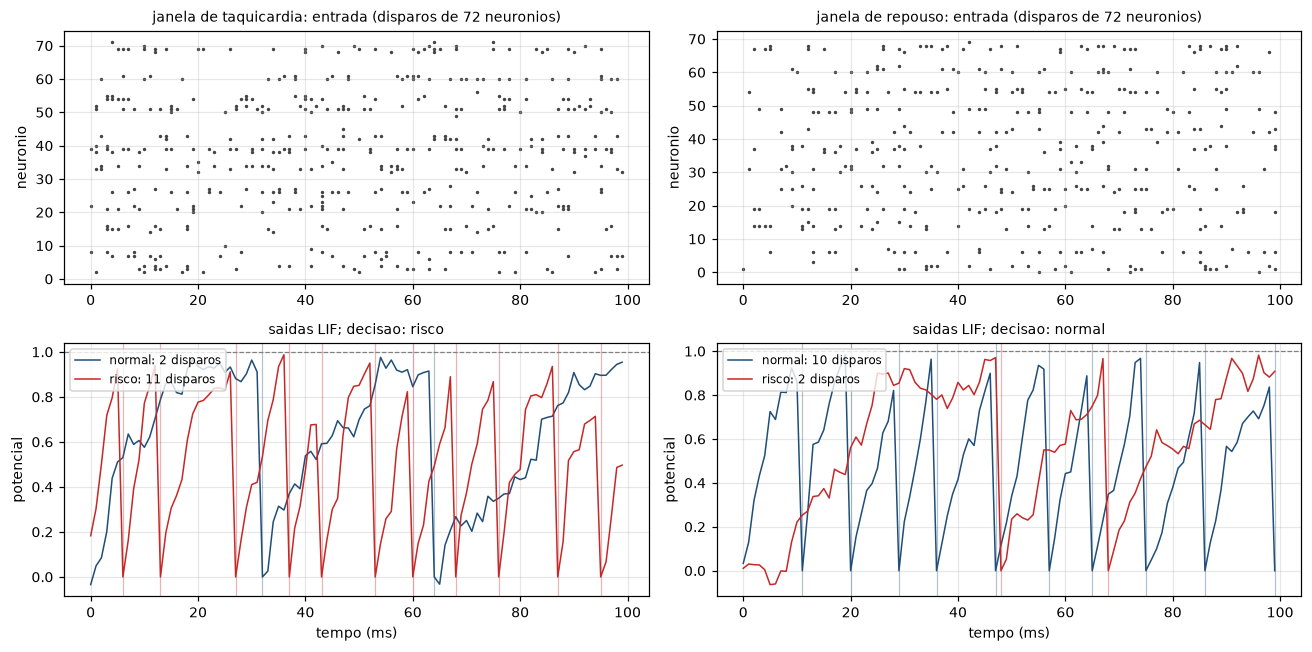

In [10]:
def painel(ax_raster, ax_v, x, titulo):
    classe, contagem, eventos, primeiro, S, traj_V, traj_s = rede.prever_janela(x, registrar=True)
    tt, nn = np.nonzero(S)
    ax_raster.scatter(tt, nn, s=1.5, color="#444444")
    ax_raster.set_title(f"{titulo}: entrada (disparos de {rede.n_in} neuronios)", fontsize=9); ax_raster.set_ylabel("neuronio")
    for k, (nome, cor) in enumerate([("normal", "#1f4e79"), ("risco", "#c62828")]):
        ax_v.plot(traj_V[:, k], color=cor, lw=1, label=f"{nome}: {int(contagem[k])} disparos")
        for t in np.nonzero(traj_s[:, k])[0]:
            ax_v.axvline(t, color=cor, alpha=0.35, lw=0.8)
    ax_v.axhline(rede.v_th, color="gray", ls="--", lw=0.8); ax_v.set_xlabel("tempo (ms)"); ax_v.set_ylabel("potencial"); ax_v.legend(fontsize=8, loc="upper left")
    ax_v.set_title(f"saidas LIF; decisao: {'risco' if classe else 'normal'}", fontsize=9)

idx_risco = np.where((sub_te == "risco_taquicardia"))[0][0]
idx_normal = np.where((sub_te == "normal_repouso"))[0][0]
fig, eixos = plt.subplots(2, 2, figsize=(12, 6))
painel(eixos[0, 0], eixos[1, 0], X_te[idx_risco], "janela de taquicardia")
painel(eixos[0, 1], eixos[1, 1], X_te[idx_normal], "janela de repouso")
fig.tight_layout(); fig.savefig(PASTA_FIG / "lif_raster_potencial.png", bbox_inches="tight"); plt.show()

## 7. Comparação entre os métodos

### 7.1 Métricas e matrizes de confusão

,acuracia,precisao,sensibilidade,f1,tempo de inferencia por janela,tempo de treino
Regra de limiares (firmware),0.897,0.842,0.978,0.905,desprezivel,nao se aplica
Regressao logistica,1.000,1.000,1.000,1.000,1 us,2 ms
Rede LIF,0.983,0.989,0.978,0.983,0.3 ms,3 s


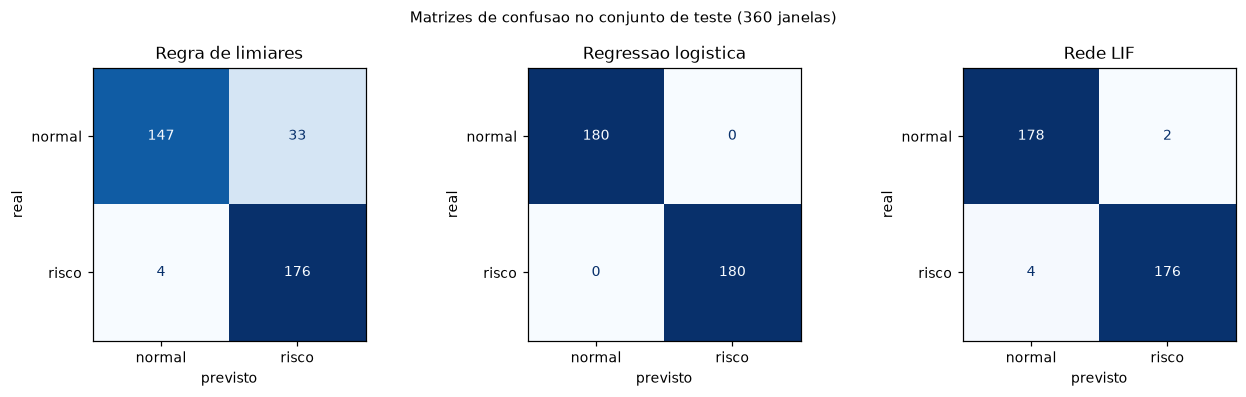

acerto por subtipo no teste:


,regra,regressao logistica,rede LIF
normal_atividade,0.426,1.0,0.963
normal_repouso,0.984,1.0,1.000
risco_arritmia,0.944,1.0,0.944
risco_bradicardia,1.000,1.0,1.000
risco_taquicardia,1.000,1.0,1.000


In [11]:
tabela = pd.DataFrame({"Regra de limiares (firmware)": res_regra, "Regressao logistica": res_rl, "Rede LIF": res_lif}).T
tabela["tempo de inferencia por janela"] = ["desprezivel", f"{tempo_inf_rl*1e6:.0f} us", f"{tempo_inf_lif*1000:.1f} ms"]
tabela["tempo de treino"] = ["nao se aplica", f"{tempo_treino_rl*1000:.0f} ms", f"{tempo_treino_lif:.0f} s"]
display(tabela.round(3))

fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6))
for eixo, (nome, pred) in zip(eixos, [("Regra de limiares", y_regra), ("Regressao logistica", y_rl), ("Rede LIF", y_lif)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["normal", "risco"]).plot(ax=eixo, colorbar=False, cmap="Blues")
    eixo.set_title(nome); eixo.set_xlabel("previsto"); eixo.set_ylabel("real"); eixo.grid(False)
fig.suptitle(f"Matrizes de confusao no conjunto de teste ({len(y_te)} janelas)", fontsize=10)
fig.tight_layout(); fig.savefig(PASTA_FIG / "matrizes_confusao.png", bbox_inches="tight"); plt.show()

acerto = pd.DataFrame({"regra": y_regra == y_te, "regressao logistica": y_rl == y_te, "rede LIF": y_lif == y_te}, index=sub_te).groupby(level=0).mean().round(3)
print("acerto por subtipo no teste:"); display(acerto)

### 7.2 Custo computacional e latência de decisão

A regressão logística decide com doze multiplicações e somas e uma função logística: custo fixo e mínimo, adequado a qualquer microcontrolador. A rede LIF, simulada em NumPy em uma CPU convencional, percorre 100 passos de tempo e processa cada disparo de entrada como um evento sináptico; o número de eventos por janela, medido abaixo, mostra o custo em uma arquitetura Von Neumann, que é justamente o cenário em que o capítulo 3 do curso (Freitas et al., 2023) observou que redes impulsionais não trazem vantagem energética. Em hardware neuromórfico orientado a eventos (TrueNorth, Loihi), o custo escala com o número de disparos e não com o número de passos, e a rede pode decidir assim que uma saída acumula vantagem: a latência medida abaixo é o instante em que a saída vencedora supera a outra por dois disparos.

In [12]:
eventos, latencias, decisoes_antecipadas_corretas = [], [], 0
for i in range(len(X_te)):
    classe, contagem, ev, primeiro, S, traj_V, traj_s = rede.prever_janela(X_te[i], registrar=True)
    eventos.append(ev)
    acumulado = np.cumsum(traj_s, axis=0)
    vantagem = np.abs(acumulado[:, 0] - acumulado[:, 1]) >= 2
    t_dec = int(np.argmax(vantagem)) if vantagem.any() else rede.T
    latencias.append(t_dec)
    classe_antecipada = int(np.argmax(acumulado[t_dec])) if t_dec < rede.T else classe
    decisoes_antecipadas_corretas += int(classe_antecipada == y_te[i])
print(f"eventos sinapticos por janela: media {np.mean(eventos):.0f} (regressao logistica: {X_te.shape[1]} multiplicacoes e somas)")
print(f"latencia da decisao (vantagem de 2 disparos): mediana {np.median(latencias):.0f} ms, percentil 90 {np.percentile(latencias, 90):.0f} ms, janela de {rede.T} ms")
print(f"acuracia da decisao antecipada: {decisoes_antecipadas_corretas / len(X_te):.3f} (decisao ao fim da janela: {res_lif['acuracia']:.3f})")
pesos = pd.DataFrame(rede.W.reshape(len(NOMES_CARACT), rede.n_rf, 2)[:, :, 1] - rede.W.reshape(len(NOMES_CARACT), rede.n_rf, 2)[:, :, 0],
                     index=NOMES_CARACT, columns=[f"rf {c:.1f}" for c in rede.centros])
print("\npeso liquido (risco menos normal) por caracteristica e campo receptivo; valores positivos empurram para risco:")
display(pesos.round(2))

eventos sinapticos por janela: media 847 (regressao logistica: 12 multiplicacoes e somas)
latencia da decisao (vantagem de 2 disparos): mediana 19 ms, percentil 90 42 ms, janela de 100 ms
acuracia da decisao antecipada: 0.992 (decisao ao fim da janela: 0.983)

peso liquido (risco menos normal) por caracteristica e campo receptivo; valores positivos empurram para risco:


,rf 0.0,rf 0.2,rf 0.4,rf 0.6,rf 0.8,rf 1.0
media,0.72,-0.46,-1.11,0.63,1.11,0.38
desvio,-2.02,0.35,1.98,1.28,0.53,0.18
minimo,2.20,0.92,-1.55,-0.94,0.12,0.12
maximo,-0.08,-1.11,-0.93,0.81,1.69,0.83
p10,1.41,-0.13,-0.86,0.29,0.28,0.07
p90,0.17,-0.51,-0.80,0.47,1.25,0.78
inclinacao,0.62,-0.19,-0.66,0.67,0.69,0.31
rmssd,-1.51,-0.45,1.51,1.67,0.75,0.16
frac_acima_120,-0.39,0.08,0.02,0.69,0.88,0.57
frac_abaixo_50,-1.04,0.13,0.66,0.91,0.98,0.50


### 7.3 Discussão: vantagens e limitações

**Desempenho.** Com as mesmas características, os dois classificadores superam a regra de limiares exatamente onde ela falha por construção: na atividade física (falso alerta da regra) e na arritmia com média normal (falso negativo da regra). A regressão logística alcança o melhor resultado com custo mínimo; a rede LIF chega a desempenho da mesma ordem, com pequena perda e com variância adicional causada pela codificação estocástica, o que é esperado para uma rede de uma camada treinada por uma regra local simples.

**Interpretabilidade.** Os coeficientes padronizados da regressão logística dizem diretamente quais características empurram a decisão para risco (variabilidade, fração acima de 120 bpm em repouso, extremos). Na rede LIF a leitura é possível, mas indireta: o peso líquido por campo receptivo mostra que faixas de cada característica excitam a saída de risco, e os disparos tornam a evidência visível no tempo; em compensação, a dinâmica estocástica dificulta explicar uma decisão individual.

**Custo e adequação à borda.** Em um ESP32, a regressão logística custa dezenas de operações por janela e cabe em qualquer firmware; é a escolha para a Fase 6 em dispositivos convencionais. A rede LIF simulada em CPU é ordens de grandeza mais cara por janela, confirmando o alerta do capítulo 3: redes impulsionais só rendem em hardware orientado a eventos. Suas vantagens aparecem nesse contexto: decisão antecipada quando a evidência é forte (latência menor que a janela), processamento esparso e consumo proporcional à atividade, características valiosas em um wearable alimentado por bateria com um coprocessador neuromórfico.

**Limitações deste estudo.** Dados sintéticos com cinco subtipos não capturam toda a variedade clínica; a rede LIF tem uma única camada e uma regra de aprendizado simplificada (modelos com gradiente substituto, como snnTorch, alcançariam mais); a codificação por taxa descarta a ordem temporal fina dentro da janela, que uma codificação temporal exploraria; e a série real do protótipo é curta. Esses pontos são os próximos passos naturais para a Fase 6.

## 8. Aplicação à série real do protótipo

A série da Parte 1 (coletada no Wokwi em 30/10/2026, com o botão simulando os batimentos) é dividida em janelas de 24 amostras com passo de 12. Valores `bpm = 0` são tratados como leitura ausente e preenchidos com a última leitura válida; janelas sem nenhuma leitura válida são ignoradas. A janela que contém o episódio provocado de 150 bpm deve ser classificada como risco pelos dois modelos; as demais, como normal.

In [13]:
def janelas_prototipo(df, tamanho=N_AMOSTRAS, passo=12):
    bpm = df.bpm.replace(0, np.nan).ffill()
    mov = df.mov.values
    saida = []
    for ini in range(0, len(df) - tamanho + 1, passo):
        b = bpm.iloc[ini:ini + tamanho]
        if b.isna().all():
            continue
        b = b.bfill().values
        saida.append({"inicio_s": int(df.ts.iloc[ini]), "fim_s": int(df.ts.iloc[ini + tamanho - 1]), "bpm_max": int(b.max()), "bpm_min": int(b.min()),
                      "x": caracteristicas(b, mov[ini:ini + tamanho])})
    return saida

jan = janelas_prototipo(proto1)
Xp = np.vstack([j["x"] for j in jan])
rede.rng = np.random.default_rng(SEMENTE)
resultado = pd.DataFrame({"inicio (s)": [j["inicio_s"] for j in jan], "fim (s)": [j["fim_s"] for j in jan], "bpm min": [j["bpm_min"] for j in jan],
                          "bpm max": [j["bpm_max"] for j in jan], "regra": regra_limiares(Xp), "regressao logistica": modelo_rl.predict(Xp),
                          "prob. risco (RL)": modelo_rl.predict_proba(Xp)[:, 1].round(3), "rede LIF": rede.prever(Xp)})
display(resultado)

,inicio (s),fim (s),bpm min,bpm max,regra,regressao logistica,prob. risco (RL),rede LIF
0,3,118,80,80,0,0,0.002,0
1,63,178,80,150,1,1,0.998,1
2,123,238,80,150,1,1,0.999,1


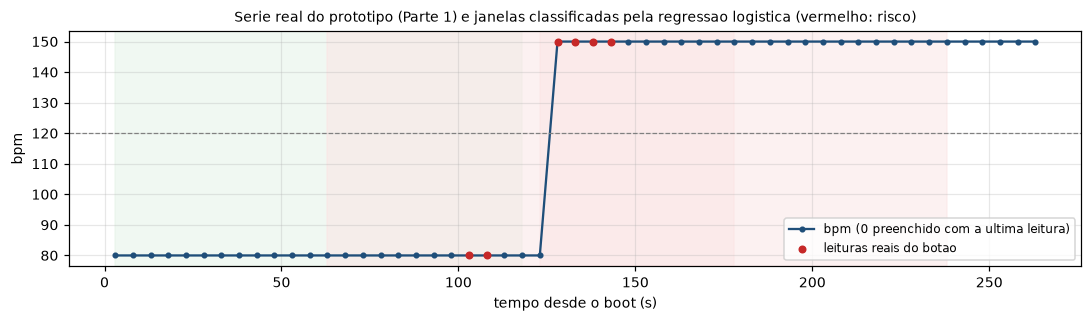

In [14]:
fig, eixo = plt.subplots(figsize=(10, 3))
serie = proto1.bpm.replace(0, np.nan).ffill().bfill()
eixo.plot(proto1.ts, serie, marker="o", ms=3, color="#1f4e79", label="bpm (0 preenchido com a ultima leitura)")
eixo.scatter(proto1.ts[proto1.bpm > 0], proto1.bpm[proto1.bpm > 0], color="#c62828", s=18, zorder=3, label="leituras reais do botao")
eixo.axhline(120, color="gray", ls="--", lw=0.8)
for _, r in resultado.iterrows():
    cor = "#fbe4e4" if r["regressao logistica"] else "#e3f2e6"
    eixo.axvspan(r["inicio (s)"], r["fim (s)"], color=cor, alpha=0.5)
eixo.set_xlabel("tempo desde o boot (s)"); eixo.set_ylabel("bpm"); eixo.set_title("Serie real do prototipo (Parte 1) e janelas classificadas pela regressao logistica (vermelho: risco)", fontsize=9)
eixo.legend(fontsize=8); fig.tight_layout(); fig.savefig(PASTA_FIG / "prototipo_janelas.png", bbox_inches="tight"); plt.show()

## 9. Conclusões

1. Em janelas de 2 minutos de frequência cardíaca, um classificador aprendido supera a regra de limiares fixos do firmware nos dois casos em que ela falha por construção: a atividade física (falso alerta) e a arritmia com média normal (falso negativo). A regressão logística obteve o melhor desempenho com o menor custo.
2. A rede neuromórfica simples, com codificação por taxa e dois neurônios LIF treinados por uma regra delta de taxa, resolve o mesmo problema com desempenho da mesma ordem, oferece decisão antecipada e processamento orientado a eventos, mas, simulada em uma CPU convencional, custa ordens de grandeza mais por janela, em linha com o capítulo 3 do curso sobre redes impulsionais em arquitetura Von Neumann.
3. Para o CardioIA, a recomendação é usar a regressão logística (ou modelos igualmente leves) no dispositivo e na API das Fases 3 e 6, mantendo os limiares fixos como rede de segurança, e reservar as redes impulsionais para um eventual coprocessador neuromórfico no wearable.
4. Os resultados vêm de dados sintéticos documentados; a validação com séries reais, com rótulos clínicos e janelas mais longas, é o passo seguinte, junto com modelos LIF multicamadas treinados por gradiente substituto.

## Referências

FIAP. Cérebros de Silício na Era dos Chips Neuromórficos. Capítulo 3 do material didático da Fase 3, 2º ano, curso de Inteligência Artificial. São Paulo: FIAP, 2025.

FREITAS, E. P. et al. Análise de Consumo de Algoritmos SNN Executados em IoT. 2023. (Conforme apresentado no capítulo 3 do material do curso.)

GERSTNER, W.; KISTLER, W. M.; NAUD, R.; PANINSKI, L. Neuronal Dynamics: From Single Neurons to Networks and Models of Cognition. Cambridge: Cambridge University Press, 2014. Disponível em: https://neuronaldynamics.epfl.ch/. Acesso em: 31 out. 2026.

PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. Journal of Machine Learning Research, v. 12, p. 2825-2830, 2011.

ESHRAGHIAN, J. K. et al. Training Spiking Neural Networks Using Lessons From Deep Learning. Proceedings of the IEEE, v. 111, n. 9, p. 1016-1054, 2023. (snnTorch.)

SHAFFER, F.; GINSBERG, J. P. An Overview of Heart Rate Variability Metrics and Norms. Frontiers in Public Health, v. 5, 258, 2017.